<div align="center">

# 🧠 DAY 03 — THE ECONOMICS OF LLMs
### Context Windows · Token Budgets · API Costs · Prompt Caching · Production Optimization

**AI Engineering Masterclass** · **Agentic AI — Core Track** · **Hands-on Jupyter Lab**

`BEGINNER → PRACTITIONER` &nbsp; • &nbsp; `NO API KEY REQUIRED FOR CORE LABS` &nbsp; • &nbsp; `UPDATED 24 NOV 2026`

---

**Build mental models → experiment with token budgets → estimate real costs → architect a caching strategy**

</div>

> **Day 3 learning outcomes.** By the end, you can (1) explain context capacity vs generated output limits, (2) compute safe request budgets, (3) estimate per-request and monthly bills, (4) distinguish cached input from uncached input and cache writes, (5) explain why stable prefixes improve cache eligibility, and (6) reason about quality/cost trade-offs in a real application.

**Learning map**

| Module | Skill | Lab |
|---|---|---|
| 01 | Context window fundamentals | Draw an input/output token budget |
| 02 | Token counting in practice | Compare text token counts |
| 03 | Growing conversations | Simulate multi-turn history |
| 04 | API billing | Build a transparent cost calculator |
| 05 | Prompt caching | Simulate hit rates, write costs, savings |
| 06 | Cache-friendly prompts | Order stable vs dynamic context |
| 07 | Production optimization | Forecast cost at scale |
| 08 | Mini-project | Implement a request budget planner |
| 09 | Optional real API | Observe usage fields on a real response |
| 10 | Review | Quiz + interview challenges |

**Prerequisites:** Day 1 (API calling) and Day 2 (tokenization). No paid API usage is needed for the core exercises.

## 0 · Install your toolkit

From this notebook's project directory:

```powershell
uv init --bare --python 3.12
uv add tiktoken matplotlib pandas numpy ipykernel python-dotenv openai
uv sync
uv run python -m ipykernel install --user --name day-03-context-cost --display-name "Python (Day 03 — Context & Cost)"
```

Use the kernel **Python (Day 03 — Context & Cost)** in VS Code. If your `pyproject.toml` already exists, **skip `uv init`**.

No secrets are needed for the main lessons. Keep `.env`, `.venv`, and notebook outputs containing sensitive information out of GitHub.

In [8]:
from dataclasses import dataclass
from math import ceil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 75)
print("✅ Day 03 lab is ready. Core exercises do not call any API.")

✅ Day 03 lab is ready. Core exercises do not call any API.


---
# 01 · What is a context window?

A **context window** is the capacity of tokens the model can process in a request, including its supplied context and (subject to model-specific rules) the tokens it generates. Think of it as the model's **working desk**, not long-term memory.

- **Input tokens:** instructions, user messages, tool results, retrieved chunks, prior turns, and any other included context.
- **Output tokens:** the model's response, potentially including reasoning tokens for supported reasoning models.
- **Reserved output budget:** space you leave available so the response is not cut short.
- **Maximum output limit:** an additional model-specific cap that can be smaller than the context window.

**Important:** Some APIs impose separate limits or handle context and output capacity in model-specific ways. Always consult the documentation for the model you actually deploy.

```text
                  MODEL CONTEXT CAPACITY (example: 32,000 tokens)
┌────────────────────────────────────────────────────────────────────────────┐
│ SYSTEM │ HISTORY │ RETRIEVED EVIDENCE │ USER │ AVAILABLE ANSWER BUDGET      │
└────────────────────────────────────────────────────────────────────────────┘
      <------------------- INPUT ---------------->  <------ OUTPUT ---------->
```

A large context window does **not** mean perfect recall or equal attention to every token; retrieval quality, truncation, and information placement still matter.

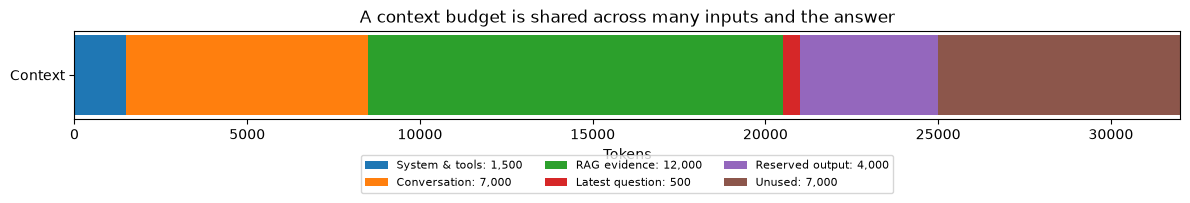

Remaining safety headroom: 7,000 tokens


In [9]:
context_limit = 32_000  # FICTIONAL LAB MODEL, not a vendor specification
parts = {"System & tools": 1_500, "Conversation": 7_000, "RAG evidence": 12_000,
         "Latest question": 500, "Reserved output": 4_000}
remaining = context_limit - sum(parts.values())
fig, ax = plt.subplots(figsize=(12, 2.5))
left = 0
for label, amount in parts.items():
    ax.barh(["Context"], [amount], left=left, label=f"{label}: {amount:,}")
    left += amount
ax.barh(["Context"], [remaining], left=left, label=f"Unused: {remaining:,}")
ax.set_xlim(0, context_limit)
ax.set_xlabel("Tokens")
ax.set_title("A context budget is shared across many inputs and the answer")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()
print(f"Remaining safety headroom: {remaining:,} tokens")

### Quick checkpoint

A model has a **32k** context capacity. Your input uses **29k** tokens and you want up to **6k** generated tokens. Is the plan safe? **No**—the total would be **35k**, even before any hidden overhead. Reduce input or output requirements, or select a suitable model.

---
# 02 · Count tokens instead of guessing

Character count, word count, and token count are **not interchangeable**. Token count depends on the tokenizer and content. Code, JSON, emojis, and multilingual text can behave differently.

We'll use `tiktoken` locally for a useful approximation on compatible OpenAI tokenizers. **For actual billing, the API's reported usage is authoritative.**

In [10]:
import tiktoken
enc = tiktoken.get_encoding("o200k_base")
examples = [
    "Hello, world!",
    "Explain context windows like I'm five.",
    '{"property_type":"SFR","square_feet":2100,"price":450000}',
    "வணக்கம்! எப்படி இருக்கிறீர்கள்?",
    "AI agents 🤖 can call tools ⚙️",
    "def predict(x): return x * 2",
]
counts = pd.DataFrame([{"text": s, "characters": len(s), "words (rough)": len(s.split()),
                        "tokens": len(enc.encode(s))} for s in examples])
display(counts)
print("Notice: an emoji or a non-English string does not equal one token.")

,text,characters,words (rough),tokens
0,"Hello, world!",13,2,4
1,Explain context windows like I'm five.,38,6,7
2,"{""property_type"":""SFR"",""square_feet"":2100,""price"":450000}",57,1,19
3,வணக்கம்! எப்படி இருக்கிறீர்கள்?,31,3,10
4,AI agents 🤖 can call tools ⚙️,29,7,10
5,def predict(x): return x * 2,28,6,9


Notice: an emoji or a non-English string does not equal one token.


**Thought experiment:** If your application ingests a 100-page PDF, does the model automatically see all 100 pages? No. Your pipeline decides what text to extract, retrieve, and place in the current request. Those included tokens consume the budget.

---
# 03 · Why long conversations become expensive

In a **stateless full-history chat implementation**, each new API request sends the selected prior messages again. That can make input token usage increase each turn. Provider-managed conversation state can simplify history handling, but does not necessarily make history free or eliminate context limits. Check each API's billing and state documentation.

### Controlled simulation

Assume each user message adds 120 tokens; each assistant reply adds 240 tokens; an instruction prefix adds 800 tokens. On turn 1, send the user message. On later turns, send the accumulated selected history.

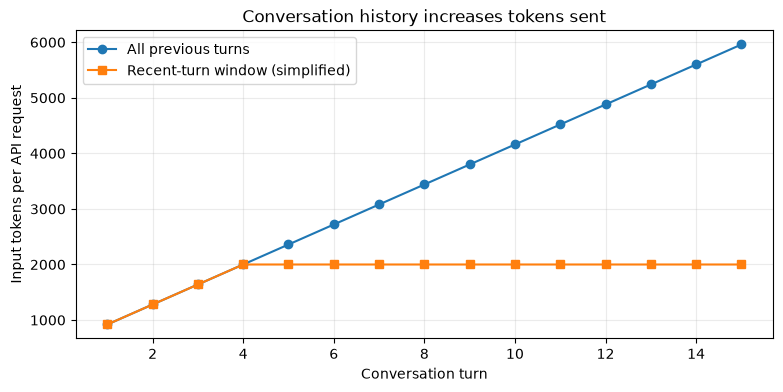

Full history across 15 calls: 51,600 billed-input token occurrences
Recent history across 15 calls: 27,840 billed-input token occurrences


In [11]:
turns = 15
system_tokens, user_per_turn, assistant_per_turn = 800, 120, 240
history_inputs = [system_tokens + t * user_per_turn + (t - 1) * assistant_per_turn for t in range(1, turns + 1)]
rolling_inputs = [system_tokens + min(t, 4) * user_per_turn + min(t - 1, 3) * assistant_per_turn for t in range(1, turns + 1)]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, turns + 1), history_inputs, marker="o", label="All previous turns")
ax.plot(range(1, turns + 1), rolling_inputs, marker="s", label="Recent-turn window (simplified)")
ax.set(xlabel="Conversation turn", ylabel="Input tokens per API request", title="Conversation history increases tokens sent")
ax.legend(); ax.grid(alpha=.25); plt.show()
print(f"Full history across {turns} calls: {sum(history_inputs):,} billed-input token occurrences")
print(f"Recent history across {turns} calls: {sum(rolling_inputs):,} billed-input token occurrences")

**Common strategies:** keep a limited recent-turn window, summarize older history, selectively retrieve relevant history, or use a stateful API where appropriate. Each trades off information fidelity, latency, engineering effort, and cost. A summary can omit important details—evaluate answer quality, not only token savings.

---
# 04 · How an LLM API bill is calculated

At the simplest level, providers can charge different rates for:

1. **Uncached input tokens** — new prompt context at the standard input rate.
2. **Cached input tokens** — eligible reused context at a cached-input rate.
3. **Output tokens** — generated response (including applicable reasoning output).
4. **Cache writes** — when supported, putting prompt content into a longer-lived cache may carry a distinct write rate.
5. **Other charges** — web search, tools, audio/image/video, priority tiers, hosting, or other provider-specific fees.

> Rates are typically quoted in **USD per million tokens**. Divide token totals by 1,000,000 before multiplying by a rate.

### Snapshot vs live price

The following **illustrative lab rate card** is NOT a current vendor price quote. You may enter your actual prices from official docs into the function. API prices and cache rules can change; some models use different rate tiers at long context lengths.

Official pricing: https://developers.openai.com/api/docs/pricing

Official caching guide: https://developers.openai.com/api/docs/guides/prompt-caching

In [12]:
@dataclass(frozen=True)
class RateCard:
    input_per_million: float
    output_per_million: float
    cached_input_per_million: float
    cache_write_per_million: float | None = None

LAB_RATES = RateCard(input_per_million=2.00, output_per_million=8.00,
                     cached_input_per_million=0.20, cache_write_per_million=2.50)

def estimate_cost(*, ordinary_input=0, cached_input=0, output=0, cache_write=0,
                  rates=LAB_RATES, extra_fees=0.0):
    values = [ordinary_input, cached_input, output, cache_write]
    if any(v < 0 for v in values) or extra_fees < 0:
        raise ValueError("Token counts and fees must be non-negative")
    if cache_write and rates.cache_write_per_million is None:
        raise ValueError("Specify a write price for this cache-write scenario")
    components = {
        "ordinary_input": ordinary_input / 1_000_000 * rates.input_per_million,
        "cached_input": cached_input / 1_000_000 * rates.cached_input_per_million,
        "output": output / 1_000_000 * rates.output_per_million,
        "cache_write": cache_write / 1_000_000 * (rates.cache_write_per_million or 0),
        "other_fees": extra_fees,
    }
    return {**components, "total": sum(components.values())}

example = estimate_cost(ordinary_input=2_000, cached_input=6_000, output=1_000)
display(pd.Series(example, name="Cost in USD").to_frame())
print(f"Total: ${example['total']:.6f}")

,Cost in USD
ordinary_input,0.0040
cached_input,0.0012
output,0.0080
cache_write,0.0000
other_fees,0.0000
total,0.0132


Total: $0.013200


**Avoid double-counting.** Cached input is a subset of total input in many usage reports: `ordinary_input = total_input - cached_input` (then account for any separately reported cache-write categories according to provider docs). Do not charge cached tokens twice.

**Billing arithmetic example:** 2,000 ordinary input × $2/M + 6,000 cached × $0.20/M + 1,000 output × $8/M = **$0.0132** at the **invented lab rates**.

### Cost sensitivity: why output tokens matter

At the sample rates, one output token is 4× the uncached input price. Long answers may cost more than surprisingly large prompts. The ratio varies by model and billing tier.

In [13]:
output_sizes = [250, 500, 1_000, 2_000, 4_000]
rows = []
for out in output_sizes:
    cost = estimate_cost(ordinary_input=8_000, output=out)["total"]
    rows.append({"output_tokens": out, "cost_per_request_USD": cost,
                 "cost_per_100k_requests_USD": cost * 100_000})
display(pd.DataFrame(rows).style.format({"cost_per_request_USD":"${:.4f}", "cost_per_100k_requests_USD":"${:,.2f}"}))

,output_tokens,cost_per_request_USD,cost_per_100k_requests_USD
0,250,$0.0180,"$1,800.00"
1,500,$0.0200,"$2,000.00"
2,1000,$0.0240,"$2,400.00"
3,2000,$0.0320,"$3,200.00"
4,4000,$0.0480,"$4,800.00"


---
# 05 · What is prompt caching?

**Prompt caching** reuses previously processed, eligible **matching prompt prefixes**. For many API systems, matching a common initial portion of the prompt is more useful than repeating identical text in arbitrary locations.

```text
REQUEST A                        REQUEST B
┌─────────────────────────┐      ┌─────────────────────────┐
│ Stable system policy    │      │ Stable system policy    │  ← shared prefix
│ Tool definitions        │      │ Tool definitions        │  ← shared prefix
│ Product documentation   │      │ Product documentation   │  ← shared prefix
├─────────────────────────┤      ├─────────────────────────┤
│ Question: How much?     │      │ Question: What changed? │  ← dynamic suffix
└─────────────────────────┘      └─────────────────────────┘
```

**Important distinctions:**

- Cache eligibility is **not guaranteed** by making requests look similar.
- Thresholds, expiration, cache-write pricing, automatic routing, and usage-field names depend on the **model/provider**.
- A cache hit generally reduces **input processing cost and sometimes latency**, but **does not mean the answer is cached**.
- A prompt cache is **not conversation memory**, and it is **not a semantic answer cache**.
- Stable prefix ordering is a strong practical technique, but actual hits must be measured in usage logs.

For OpenAI, see the live [prompt caching guide](https://developers.openai.com/api/docs/guides/prompt-caching) for current eligibility, TTL, and per-model cache behavior.

### Cache economics (including write fees)

At the lab rate card, consider a batch of requests. Each has 10k input tokens (8k stable + 2k changing) and 1k output. Assume one initial request writes an 8k prefix at a write rate; subsequent requests hit the cache on that prefix. This is a **controlled idealized scenario**, not a guarantee of real hit behavior.

In [14]:
requests = 100
stable, changing, generated = 8_000, 2_000, 1_000
baseline = requests * estimate_cost(ordinary_input=stable+changing, output=generated)["total"]
first = estimate_cost(ordinary_input=changing, cache_write=stable, output=generated)["total"]
following = (requests - 1) * estimate_cost(ordinary_input=changing, cached_input=stable, output=generated)["total"]
with_cache = first + following
print(f"Without caching: ${baseline:.4f}")
print(f"With idealized prefix reuse and one billed write: ${with_cache:.4f}")
print(f"Illustrative savings: {(baseline-with_cache)/baseline:.1%}")
print("Real-world costs depend on misses, expiry, model rules, and write billing.")

Without caching: $2.8000
With idealized prefix reuse and one billed write: $1.3784
Illustrative savings: 50.8%
Real-world costs depend on misses, expiry, model rules, and write billing.


### Simulate cache-hit rate (and break-even intuition)

For clarity, this next function models each **miss** as writing the stable prefix at the lab write rate. Different providers may bill cache writes differently. It keeps output cost unchanged across scenarios.

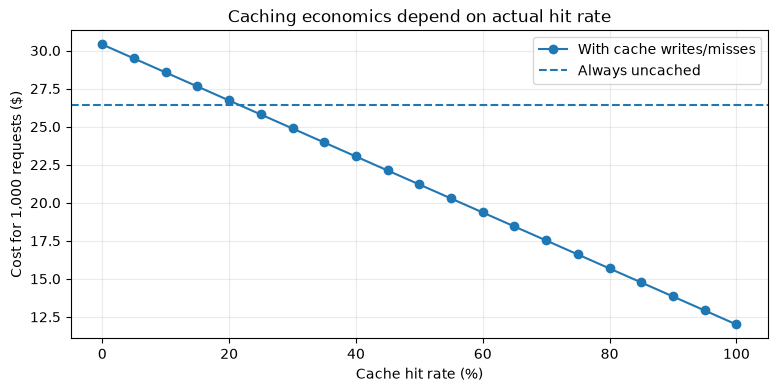

,hit_rate,estimated_USD
0,0%,$30.40
5,25%,$25.80
10,50%,$21.20
15,75%,$16.60
20,100%,$12.00


In [15]:
def simulate_cache(hit_rate, n_requests=1000, stable=8_000, dynamic=2_000, output=800, rates=LAB_RATES):
    hits = int(round(n_requests * hit_rate))
    misses = n_requests - hits
    total = (
        misses * estimate_cost(ordinary_input=dynamic, cache_write=stable, output=output, rates=rates)["total"]
        + hits * estimate_cost(ordinary_input=dynamic, cached_input=stable, output=output, rates=rates)["total"]
    )
    return total

hit_rates = np.linspace(0, 1, 21)
scenario = pd.DataFrame({"hit_rate": hit_rates,
                         "estimated_USD": [simulate_cache(h) for h in hit_rates]})
uncached = 1000 * estimate_cost(ordinary_input=10_000, output=800)["total"]
fig, ax = plt.subplots(figsize=(9,4))
ax.plot(scenario["hit_rate"]*100, scenario["estimated_USD"], marker="o", label="With cache writes/misses")
ax.axhline(uncached, linestyle="--", label="Always uncached")
ax.set(xlabel="Cache hit rate (%)", ylabel="Cost for 1,000 requests ($)", title="Caching economics depend on actual hit rate")
ax.legend(); ax.grid(alpha=.25); plt.show()
display(scenario.iloc[[0,5,10,15,20]].style.format({"hit_rate":"{:.0%}","estimated_USD":"${:.2f}"}))

---
# 06 · Design cache-friendly prompts

Put stable information **first**, and request-specific information **last**. Keep instructions, tool schemas, and documents stable between requests when feasible. Prefix matching can be disrupted by timestamps, user IDs, reordered sections, or other frequently changing content placed at the beginning.

**Poor organization**

```text
Current time: [new timestamp every call]
Customer question: [different each call]
System policy: [identical for every call]
Product manual: [identical for every call]
```

**Better organization**

```text
System policy: [identical]
Product manual: [identical]
Current time: [varies]
Customer question: [varies]
```

Do not compromise privacy or accuracy merely to force a cache hit. Account for tenant isolation, retention requirements, and the provider's actual cache semantics.

In [16]:
stable_policy = "You are a helpful support assistant. Follow company policy. " * 40
manual = "Refunds are available within 30 days with a receipt. " * 60
question_a, question_b = "Can I request a refund?", "What if I lost my receipt?"

def common_prefix_tokens(a, b, tokenizer=enc):
    aa, bb = tokenizer.encode(a), tokenizer.encode(b)
    return next((i for i,(x,y) in enumerate(zip(aa, bb)) if x != y), min(len(aa),len(bb)))

bad_a = f"Question: {question_a}\n{stable_policy}\n{manual}"
bad_b = f"Question: {question_b}\n{stable_policy}\n{manual}"
good_a = f"{stable_policy}\n{manual}\nQuestion: {question_a}"
good_b = f"{stable_policy}\n{manual}\nQuestion: {question_b}"
print("Bad layout matching prefix tokens:", common_prefix_tokens(bad_a,bad_b))
print("Better layout matching prefix tokens:", common_prefix_tokens(good_a,good_b))
print("Note: shared prefix length is a proxy, not an API cache-hit guarantee.")

Bad layout matching prefix tokens: 2
Better layout matching prefix tokens: 1164
Note: shared prefix length is a proxy, not an API cache-hit guarantee.


---
# 07 · Capacity planning at production scale

For product budgeting, you care about more than a single call: traffic volume, re-tries, agent/tool loops, cache-hit rate, average tokens, variance, and budget caps.

**Simplified monthly estimate:**

`monthly USD ≈ requests/day × days × mean cost/request × (1 + retry_fraction)`

For **agents**, one user request may cause several model calls. Measure calls per task, not just tasks per day.

In [17]:
def monthly_forecast(daily_tasks=5000, days=30, calls_per_task=2.0,
                     retry_fraction=0.05, input_tokens=4000, output_tokens=600,
                     cached_share=0.25, rates=LAB_RATES):
    if not (0 <= cached_share <= 1): raise ValueError("cached_share must be 0..1")
    billable_calls = daily_tasks * days * calls_per_task * (1 + retry_fraction)
    unit = estimate_cost(ordinary_input=input_tokens*(1-cached_share),
                         cached_input=input_tokens*cached_share,
                         output=output_tokens, rates=rates)["total"]
    return {"estimated_calls": billable_calls,
            "cost_per_call_USD": unit,
            "monthly_cost_USD": billable_calls * unit}

for tasks in [500, 5_000, 50_000]:
    estimate = monthly_forecast(daily_tasks=tasks)
    print(f"{tasks:>6,} daily tasks → {estimate['estimated_calls']:>10,.0f} calls / month → ${estimate['monthly_cost_USD']:>10,.2f}")
print("Assumes lab rates and no separate cache writes or tool fees.")

   500 daily tasks →     31,500 calls / month → $    346.50
 5,000 daily tasks →    315,000 calls / month → $  3,465.00
50,000 daily tasks →  3,150,000 calls / month → $ 34,650.00
Assumes lab rates and no separate cache writes or tool fees.


### Production recommendations

| Lever | Typical benefit | Main risk / consideration |
|---|---|---|
| Shorter prompts | Less input cost | Omitting critical evidence |
| Retrieval filtering | Less irrelevant context | Missed documents |
| History summaries | Smaller long conversations | Information loss |
| Cache-friendly stable prefixes | Lower repeated-input cost | Cache eligibility not guaranteed |
| Smaller model for routine calls | Lower cost and latency | Lower quality on difficult tasks |
| Output-length control | Lower output spend | Incomplete answers |
| Batch / flexible processing | Potential price reductions | Higher or variable latency |
| Evaluations + telemetry | Find best cost/quality frontier | Requires datasets and monitoring |

**Measure:** input, cached input, cache writes, output/reasoning tokens, request volume, latency, provider billed USD, failed/retried calls, and task success rate.

---
# 08 · Mini-project: Production request budget planner

**Scenario:** You're building an enterprise property-question answering RAG app. A request includes policies, conversation history, retrieved property records, a user question, and a planned response. The app must accept, compress, or reject requests before exceeding a chosen model capacity.

Implement a transparent planner. It does not silently delete information; it shows the budget and suggests options.

In [18]:
@dataclass(frozen=True)
class RequestBudget:
    context_limit: int
    max_output: int
    system_and_tools: int
    history: int
    retrieved_context: int
    question: int
    overhead_reserve: int = 250

    def report(self):
        input_tokens = self.system_and_tools + self.history + self.retrieved_context + self.question
        required = input_tokens + self.max_output + self.overhead_reserve
        margin = self.context_limit - required
        if self.max_output > self.context_limit:
            raise ValueError("Output reservation cannot exceed the context limit")
        return {"input_tokens": input_tokens, "reserved_output": self.max_output,
                "overhead_reserve": self.overhead_reserve, "context_limit": self.context_limit,
                "headroom": margin, "fits": margin >= 0,
                "action": "Proceed" if margin >= 0 else "Trim/retrieve fewer chunks, summarize history, or change model"}

budget = RequestBudget(context_limit=16_000, max_output=2_000,
                       system_and_tools=1_200, history=5_000,
                       retrieved_context=7_000, question=300)
display(pd.Series(budget.report(), name="Value").to_frame())

,Value
input_tokens,13500
reserved_output,2000
overhead_reserve,250
context_limit,16000
headroom,250
fits,True
action,Proceed


### Challenge: make it fit

Change **only** `history` or `retrieved_context` in the cell below and produce `fits = True`. Then answer: what evidence did you remove, and how would you test that the answer is still trustworthy?

In [19]:
# Edit this budget and re-run.
new_budget = RequestBudget(context_limit=16_000, max_output=2_000,
                           system_and_tools=1_200, history=2_500,
                           retrieved_context=7_000, question=300)
result = new_budget.report()
print(result)
assert result["fits"], "Reduce the size of the request before sending it"
print("✅ Budget fit achieved; quality must still be evaluated.")

{'input_tokens': 11000, 'reserved_output': 2000, 'overhead_reserve': 250, 'context_limit': 16000, 'headroom': 2750, 'fits': True, 'action': 'Proceed'}
✅ Budget fit achieved; quality must still be evaluated.


---
# 09 · OPTIONAL: observe actual API usage

This lab calls a **real paid API** only if you explicitly set `RUN_LIVE_API = True` and configure `OPENAI_API_KEY`. It uses the Responses API. The model is configurable because availability and usage schema can change.

Example `.env` (never commit):

```text
OPENAI_API_KEY=your_key_here
OPENAI_MODEL=your_available_model_id
```

Some `usage` objects contain `input_tokens`, `output_tokens`, and breakdowns such as `input_tokens_details.cached_tokens`; the exact fields depend on the API, model, and features. Printed usage is a measurement, **not a complete invoice**.

In [20]:
RUN_LIVE_API = False  # Change only when you intend to make a paid request.

if RUN_LIVE_API:
    import os
    from dotenv import load_dotenv
    from openai import OpenAI
    load_dotenv()
    model = os.getenv("OPENAI_MODEL")
    if not os.getenv("OPENAI_API_KEY") or not model:
        raise RuntimeError("Set OPENAI_API_KEY and OPENAI_MODEL in your local .env")
    client = OpenAI()
    response = client.responses.create(
        model=model,
        input="Explain context windows in exactly two short sentences.",
        max_output_tokens=150,
    )
    print(response.output_text)
    print("Reported usage:", response.usage)
else:
    print("Safe mode: no API request sent. Set RUN_LIVE_API=True to opt in.")

Safe mode: no API request sent. Set RUN_LIVE_API=True to opt in.


### An important cache-usage nuance

For some OpenAI models, **cache writes are reported separately from cached reads**. A complete estimator needs to classify the reported token categories **without overlap** and apply your model's actual rate card. Never assume every provider/version uses the same `usage` schema.

See: https://developers.openai.com/api/docs/guides/prompt-caching

---
# 10 · Practice quiz

Try without scrolling up.

1. Does a 128k context window mean the model can always output 128k tokens?
2. If an API reports 8k input tokens, of which 5k were cached, how many were uncached? (Assume no separately reported write tokens.)
3. Is prompt caching the same as storing the model's previous answer?
4. Why might placing a timestamp at the beginning of every prompt reduce cache reuse?
5. What happens to billable input in a naive full-history chat as turns accumulate?
6. Why isn't lowering tokens sufficient to prove an optimization is successful?
7. A RAG system sends 40k of irrelevant document tokens. Name two better approaches.
8. What extra factors appear when projecting API cost for an agent with multiple tool calls?

<details><summary><b>Reveal answers</b></summary>

1. No; the context capacity and maximum generated output can be separate constraints.
2. 3k ordinary input tokens.
3. No; a prompt cache reuses input processing, not necessarily generated answers.
4. It changes the initial prefix, potentially preventing exact-prefix matches.
5. It generally increases, unless history is trimmed or managed differently.
6. Shorter prompts can lose evidence and harm quality; evaluate task metrics.
7. Retrieval filtering/reranking and selective chunking/context compression.
8. Calls/task, retries, tool charges, token variance, cache hits, and latency/quality constraints.

</details>

---
# 11 · Interview-level design challenge

> **Design a customer-support AI receiving 100,000 tasks/day.** Each task uses 3 calls, mean input is 7,000 tokens, mean output is 700 tokens, and 40% of input token usage is cached reads. Calculate the 30-day estimated spend using `monthly_forecast`, then consider: (a) What if cache hit rate drops? (b) What if the model is upgraded? (c) What if a 2,000-token retrieved chunk is frequently irrelevant? (d) How would you prevent a single runaway agent from blowing the budget?

Recommended engineering response: build a **quality-constrained cost model**, instrument actual usage, add per-user/task budgets, use context truncation policies, and validate cached-read assumptions from telemetry—not from prompt similarity alone.

In [21]:
interview = monthly_forecast(daily_tasks=100_000, days=30, calls_per_task=3,
                             retry_fraction=0, input_tokens=7_000, output_tokens=700,
                             cached_share=0.40)
display(pd.Series(interview, name="Illustrative lab forecast").to_frame())

,Illustrative lab forecast
estimated_calls,9.000000e+06
cost_per_call_USD,1.456000e-02
monthly_cost_USD,1.310400e+05


---
# 12 · One-page cheat sheet

**Capacity:** `input + reserved output + overhead ≤ supported context capacity` (subject to model-specific policies).

**Token counting:** use compatible tokenizers as estimates; trust **API usage** for billed counts.

**Uncached vs cached:** separate ordinary input from eligible cached input; account for distinct **cache-write** buckets where applicable.

**Basic cost:** `(ordinary_input × input_rate + cached_input × cached_rate + cache_write × write_rate + output × output_rate) / 1,000,000 + extra fees`.

**Cache design:** stable instructions/documentation first, variable questions last; measure hits, don't presume them.

**Production:** budget at **task level**, not just per API call; track quality, cost, latency, retries, and agent loops.

### Primary references (verify current terms before deployment)

- [OpenAI API pricing](https://developers.openai.com/api/docs/pricing)
- [OpenAI prompt caching guide](https://developers.openai.com/api/docs/guides/prompt-caching)
- [OpenAI model catalog and model-specific context windows](https://developers.openai.com/api/docs/models)
- [OpenAI Responses API guide](https://developers.openai.com/api/docs/guides/text)

**Next in the Masterclass → Day 04: embeddings, vector representations, similarity, and retrieval foundations.**

*Day 03 complete — the goal is not merely to make the LLM cheaper; it is to make the **whole system** efficient while preserving quality.*